<a href="https://colab.research.google.com/github/MazighGuirat/projet/blob/main/Sujet02_CNN_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sujet 02 : CNN & Transfer Learning — Détection de pneumonie sur radiographies

**Module Deep Learning — Master 2 Informatique (2026–2027)**

Objectifs :
1. Utiliser un **ResNet-50 pré-entraîné sur ImageNet** pour classer des radiographies (NORMAL vs PNEUMONIA).
2. Comparer **Feature Extraction** (backbone gelé) et **Fine-Tuning global**.
3. Mesurer l'apport des **augmentations de données (Albumentations)**.

Plan : données → modèle → entraînement → 4 expériences → résultats → analyse.

> Exécuter sur GPU (Colab : Exécution > Modifier le type d'exécution > GPU ; Kaggle : Accelerator > GPU).

## 1. Installation et imports

In [1]:
!pip install -q albumentations kagglehub

In [2]:
import os, glob, random, time, copy
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models

import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 6
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ["NORMAL", "PNEUMONIA"]

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
print("Device :", DEVICE)

Device : cuda


## 2. Données

Dataset : *Chest X-Ray Images (Pneumonia)* (Kaggle, `paultimothymooney/chest-xray-pneumonia`).

- Le dossier `val` d'origine ne contient que 16 images : trop petit pour être fiable. On crée donc **notre propre validation (15 %)** à partir de `train`.
- Le dossier `test` d'origine est conservé **intact** pour l'évaluation finale.
- Sur Kaggle : ajouter le dataset au notebook. Sur Colab : `kagglehub` demande vos identifiants Kaggle.

In [3]:
import kagglehub

ROOT = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

# Le dossier contient parfois un "chest_xray" imbriqué : on cherche celui qui contient train/ et test/
DATA_DIR = None
for c in glob.glob(os.path.join(ROOT, "**", "chest_xray"), recursive=True):
    if os.path.isdir(os.path.join(c, "train")) and os.path.isdir(os.path.join(c, "test")):
        DATA_DIR = c
        break
assert DATA_DIR is not None, "Dossier chest_xray introuvable"
print("DATA_DIR :", DATA_DIR)

def list_images(split):
    paths, labels = [], []
    for label, cls in enumerate(CLASSES):
        files = []
        for ext in ("*.jpeg", "*.jpg", "*.png"):
            files += glob.glob(os.path.join(DATA_DIR, split, cls, ext))
        paths += files
        labels += [label] * len(files)
    return paths, labels

train_all_p, train_all_l = list_images("train")
test_p, test_l = list_images("test")

# Validation = 15 % du train (stratifié)
train_p, val_p, train_l, val_l = train_test_split(
    train_all_p, train_all_l, test_size=0.15, stratify=train_all_l, random_state=SEED)

summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "NORMAL": [train_l.count(0), val_l.count(0), test_l.count(0)],
    "PNEUMONIA": [train_l.count(1), val_l.count(1), test_l.count(1)],
})
summary["total"] = summary["NORMAL"] + summary["PNEUMONIA"]
summary

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
DATA_DIR : /kaggle/input/chest-xray-pneumonia/chest_xray


,split,NORMAL,PNEUMONIA,total
0,train,1140,3293,4433
1,val,201,582,783
2,test,234,390,624


### Prétraitement et augmentations (Albumentations)

- **Sans augmentation** : redimensionnement 224×224 + normalisation ImageNet (obligatoire pour un modèle pré-entraîné).
- **Avec augmentation** (train uniquement) : légère rotation, translation/zoom, contraste/luminosité, CLAHE.
- On **n'utilise pas de flip horizontal** : en radiographie thoracique, l'orientation (cœur à gauche) est une information anatomique.

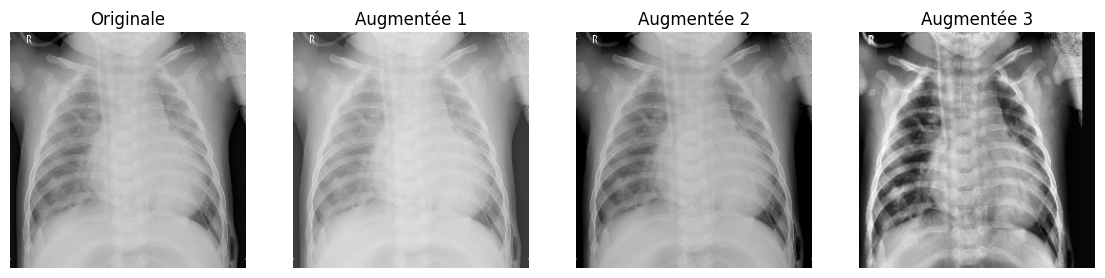

In [4]:
normalize = A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

tf_base = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    normalize,
    ToTensorV2(),
])

tf_aug = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Rotate(limit=10, p=0.7),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.7),
    A.CLAHE(p=0.3),
    normalize,
    ToTensorV2(),
])

class XRayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.imread(self.paths[i], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # ResNet attend 3 canaux
        img = self.transform(image=img)["image"]
        return img, torch.tensor(self.labels[i], dtype=torch.long)

def make_loaders(augment):
    train_ds = XRayDataset(train_p, train_l, tf_aug if augment else tf_base)
    val_ds = XRayDataset(val_p, val_l, tf_base)
    test_ds = XRayDataset(test_p, test_l, tf_base)
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True)
    return (DataLoader(train_ds, shuffle=True, **kw),
            DataLoader(val_ds, shuffle=False, **kw),
            DataLoader(test_ds, shuffle=False, **kw))

# Aperçu : une image avec et sans augmentation
sample = cv2.cvtColor(cv2.imread(train_p[0], cv2.IMREAD_GRAYSCALE), cv2.COLOR_GRAY2RGB)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(cv2.resize(sample, (IMG_SIZE, IMG_SIZE))); axes[0].set_title("Originale")
for k in range(1, 4):
    out = A.Compose([t for t in tf_aug.transforms if not isinstance(t, (A.Normalize, ToTensorV2))])(image=sample)["image"]
    axes[k].imshow(out); axes[k].set_title(f"Augmentée {k}")
for ax in axes: ax.axis("off")
plt.show()

## 3. Modèle : ResNet-50 pré-entraîné

On remplace la couche finale (1000 classes ImageNet) par une tête à 2 classes.

| Mode | Couches entraînées | Learning rate |
|---|---|---|
| **Feature Extraction** | uniquement la tête `fc` (backbone gelé, BatchNorm en mode eval) | 1e-3 |
| **Fine-Tuning global** | tout le réseau | 1e-4 (backbone), 1e-3 (tête) |

Le dataset est **déséquilibré** (~3 PNEUMONIA pour 1 NORMAL) : on utilise une **perte pondérée** par classe.

In [7]:
def build_model(mode):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    in_f = model.fc.in_features
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, 2))
    if mode == "feature_extraction":
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith("fc")
    return model.to(DEVICE)

def build_optimizer(model, mode):
    head = list(model.fc.parameters())
    if mode == "feature_extraction":
        return torch.optim.Adam(head, lr=1e-3)
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    return torch.optim.AdamW([
        {"params": backbone, "lr": 1e-4},
        {"params": head, "lr": 1e-3},
    ], weight_decay=1e-4)

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for m in ["feature_extraction", "finetune"]:
    t, tr = count_params(build_model(m))
    print(f"{m:20s} | paramètres entraînables : {tr:,} / {t:,}")

feature_extraction   | paramètres entraînables : 4,098 / 23,512,130
finetune             | paramètres entraînables : 23,512,130 / 23,512,130


## 4. Entraînement et évaluation

In [9]:
USE_AMP = DEVICE.type == "cuda"

# Poids de classes (inverse de la fréquence)
counts = np.bincount(train_l)
class_weights = torch.tensor(len(train_l) / (2.0 * counts), dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)

def set_train_mode(model, mode):
    model.train()
    if mode == "feature_extraction":
        # Backbone gelé : on fige aussi les statistiques BatchNorm
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    losses, preds, labels = [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(x)
            loss = criterion(out, y)
        losses.append(loss.item() * len(y))
        preds += out.argmax(1).cpu().tolist()
        labels += y.cpu().tolist()
    return sum(losses) / len(labels), np.array(preds), np.array(labels)

def run_experiment(mode, augment, epochs=EPOCHS):
    name = f"{'FE' if mode == 'feature_extraction' else 'FT'} | {'avec aug' if augment else 'sans aug'}"
    print(f"\n===== {name} =====")
    set_seed()
    train_loader, val_loader, test_loader = make_loaders(augment)
    model = build_model(mode)
    optimizer = build_optimizer(model, mode)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state = -1, None
    t0 = time.time()

    for ep in range(epochs):
        set_train_mode(model, mode)
        run_loss, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            run_loss += loss.item() * len(y)
            n += len(y)

        val_loss, vp, vl = predict(model, val_loader)
        val_f1 = f1_score(vl, vp)
        history["train_loss"].append(run_loss / n)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)
        print(f"Epoch {ep+1}/{epochs} | train_loss {run_loss/n:.4f} | val_loss {val_loss:.4f} | val_F1 {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1, best_state = val_f1, copy.deepcopy(model.state_dict())

    train_time = time.time() - t0

    # Évaluation finale sur le TEST avec le meilleur modèle (choisi sur la validation)
    model.load_state_dict(best_state)
    _, tp, tl = predict(model, test_loader)
    result = {
        "name": name, "mode": mode, "augment": augment,
        "accuracy": accuracy_score(tl, tp),
        "precision": precision_score(tl, tp),
        "recall": recall_score(tl, tp),
        "f1": f1_score(tl, tp),
        "train_time_s": train_time,
        "history": history,
        "cm": confusion_matrix(tl, tp),
        "report": classification_report(tl, tp, target_names=CLASSES, digits=3),
    }
    print(f"TEST -> acc {result['accuracy']:.3f} | precision {result['precision']:.3f} | "
          f"recall {result['recall']:.3f} | F1 {result['f1']:.3f}")
    return result

## 5. Les 4 expériences

| | Sans augmentation | Avec augmentation |
|---|---|---|
| **Feature Extraction** | A1 | A2 |
| **Fine-Tuning global** | B1 | B2 |

Compter environ 5 à 10 minutes par expérience sur un GPU T4.

In [10]:
results = []
for mode in ["feature_extraction", "finetune"]:
    for augment in [False, True]:
        results.append(run_experiment(mode, augment))


===== FE | sans aug =====
Epoch 1/6 | train_loss 0.2678 | val_loss 0.1632 | val_F1 0.9526
Epoch 2/6 | train_loss 0.1539 | val_loss 0.1286 | val_F1 0.9620
Epoch 3/6 | train_loss 0.1321 | val_loss 0.1126 | val_F1 0.9702
Epoch 4/6 | train_loss 0.1221 | val_loss 0.1027 | val_F1 0.9713
Epoch 5/6 | train_loss 0.1189 | val_loss 0.1098 | val_F1 0.9617
Epoch 6/6 | train_loss 0.1053 | val_loss 0.0999 | val_F1 0.9675
TEST -> acc 0.830 | precision 0.801 | recall 0.969 | F1 0.877

===== FE | avec aug =====
Epoch 1/6 | train_loss 0.3266 | val_loss 0.1774 | val_F1 0.9471
Epoch 2/6 | train_loss 0.2087 | val_loss 0.1412 | val_F1 0.9566
Epoch 3/6 | train_loss 0.1848 | val_loss 0.1309 | val_F1 0.9581
Epoch 4/6 | train_loss 0.1721 | val_loss 0.1175 | val_F1 0.9652
Epoch 5/6 | train_loss 0.1704 | val_loss 0.1190 | val_F1 0.9608
Epoch 6/6 | train_loss 0.1563 | val_loss 0.1063 | val_F1 0.9657
TEST -> acc 0.875 | precision 0.851 | recall 0.969 | F1 0.906

===== FT | sans aug =====
Epoch 1/6 | train_loss 0.15

## 6. Résultats

In [11]:
table = pd.DataFrame([{
    "Expérience": r["name"],
    "Accuracy": r["accuracy"], "Precision": r["precision"],
    "Recall": r["recall"], "F1": r["f1"],
    "Temps (s)": r["train_time_s"],
} for r in results]).set_index("Expérience").round(3)
table.to_csv("resultats_sujet02.csv")
table

,Accuracy,Precision,Recall,F1,Temps (s)
Expérience,,,,,
FE | sans aug,0.830,0.801,0.969,0.877,216.652
FE | avec aug,0.875,0.851,0.969,0.906,230.604
FT | sans aug,0.849,0.808,0.995,0.892,232.421
FT | avec aug,0.859,0.819,0.995,0.898,262.948


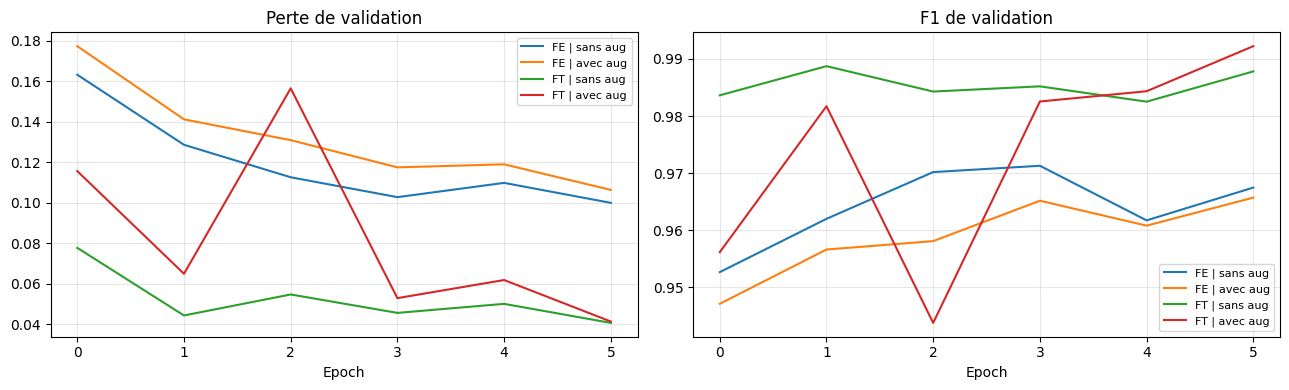

In [12]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for r in results:
    axes[0].plot(r["history"]["val_loss"], label=r["name"])
    axes[1].plot(r["history"]["val_f1"], label=r["name"])
axes[0].set_title("Perte de validation"); axes[1].set_title("F1 de validation")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("courbes_sujet02.png", dpi=150); plt.show()

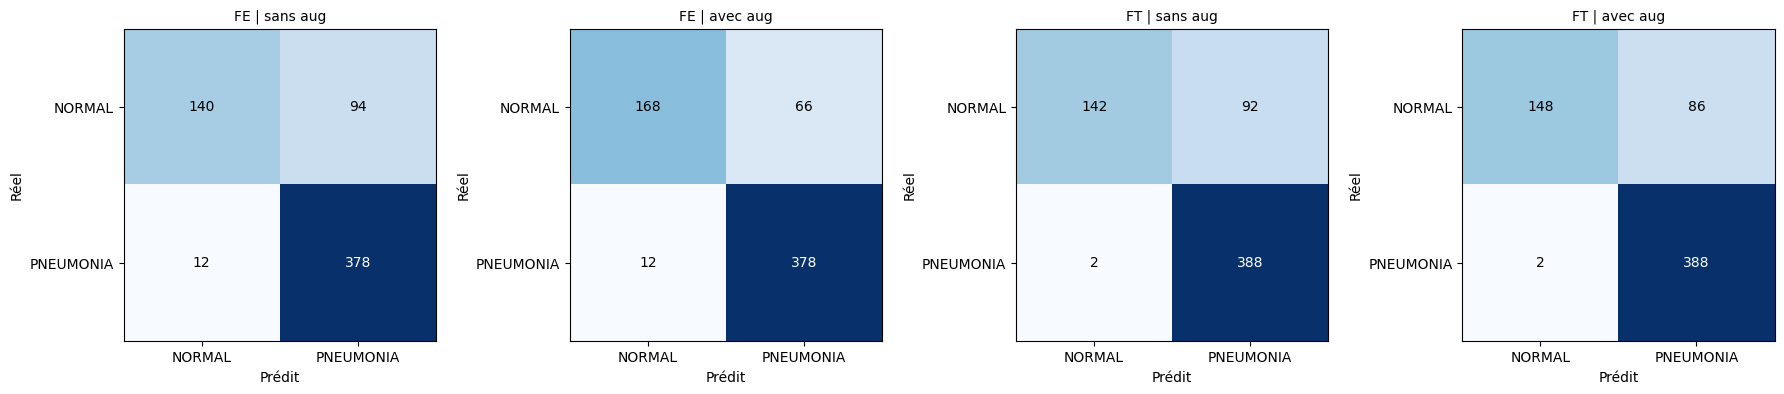


 FE | sans aug
              precision    recall  f1-score   support

      NORMAL      0.921     0.598     0.725       234
   PNEUMONIA      0.801     0.969     0.877       390

    accuracy                          0.830       624
   macro avg      0.861     0.784     0.801       624
weighted avg      0.846     0.830     0.820       624


 FE | avec aug
              precision    recall  f1-score   support

      NORMAL      0.933     0.718     0.812       234
   PNEUMONIA      0.851     0.969     0.906       390

    accuracy                          0.875       624
   macro avg      0.892     0.844     0.859       624
weighted avg      0.882     0.875     0.871       624


 FT | sans aug
              precision    recall  f1-score   support

      NORMAL      0.986     0.607     0.751       234
   PNEUMONIA      0.808     0.995     0.892       390

    accuracy                          0.849       624
   macro avg      0.897     0.801     0.822       624
weighted avg      0.875   

In [13]:
# Matrices de confusion (test)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, r in zip(axes, results):
    ax.imshow(r["cm"], cmap="Blues")
    ax.set_title(r["name"], fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(CLASSES)
    ax.set_yticks([0, 1]); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, r["cm"][i, j], ha="center", va="center",
                    color="white" if r["cm"][i, j] > r["cm"].max() / 2 else "black")
plt.tight_layout(); plt.savefig("confusion_sujet02.png", dpi=150); plt.show()

for r in results:
    print("\n", r["name"]); print(r["report"])

## 7. Analyse (à compléter avec vos résultats)

**Feature Extraction vs Fine-Tuning**
- Quelle approche obtient le meilleur F1 / recall ? Quel écart ?
- Pourquoi ? (les features ImageNet sont génériques, les radiographies ont une distribution très différente : le fine-tuning adapte les filtres au domaine médical.)
- Coût : nombre de paramètres entraînés, temps d'entraînement.

**Apport des augmentations**
- Amélioration ou non ? Effet sur l'écart train/validation (surapprentissage) ?
- Pourquoi pas de flip horizontal ?

**Métrique clé en médical**
- Le **recall** (sensibilité) est prioritaire : un faux négatif (pneumonie non détectée) est plus grave qu'un faux positif.

**Limites**
- Dataset pédiatrique unique, déséquilibré, test set de taille modeste.
- Pas de validation croisée, une seule graine (seed).
- Pas de validation clinique : projet pédagogique uniquement.

**Pistes d'amélioration** : Grad-CAM pour visualiser les zones utilisées par le modèle, dégel progressif, scheduler de learning rate, plusieurs graines.